In [11]:
import os
os.chdir(os.path.expandvars("/scratch/vp91/$USER/intro-to-cuda"))

# GPU Execution Model


> **Overview**
>
> 
>  * **Time:** 60 min
> 
>  1. Learn the CUDA execution model.
>  1. Understand the difference between CUDA kernels and functions.
>  1. Learn how to launch CUDA kernels and manage thread indexing.

CUDA (Compute Unified Device Architecture) is a parallel computing platform and programming model developed by NVIDIA. It allows developers to use a
CUDA-enabled GPU for general-purpose processing, leveraging its massive parallelism capabilities.

## CUDA Kernels vs Functions


In CUDA, both kernels and functions are used to define code behavior, but they have distinct purposes, execution models, and qualifiers.
CUDA supports three types of functions based on qualifiers:

**CUDA Function Types**

| Qualifier | Meaning |
| --- | --- |
| `__global__` | Defines a *kernel* function that runs on the device (GPU) and is called from the host (CPU). |
| `__device__` | Defines a function that runs on the device and can only be called from other device or global functions. |
| `__host__` | Defines a function that runs on the host (CPU). This is the default for C/C++ functions. |
| `__host__ __device__` | The function can be compiled for and called from both host and device. Often used for small inline functions or utilities. |

### CUDA Kernel


A kernel is a special type of function that is executed in parallel by many GPU threads. Kernels are defined using the `__global__` keyword and are launched
using triple angle brackets syntax.

```cpp
__global__ void add(int *a, int *b, int *c) {
    int i = threadIdx.x;
    c[i] = a[i] + b[i];
}

// Launch kernel with 1 block of 256 threads
add<<<1, 256>>>(d_a, d_b, d_c);
```

### CUDA Device Function


Device functions run on the GPU but are called only from other device or global functions. They are useful for modularizing GPU code.

```cpp
__device__ int add(int x, int y) {
    return x + y;
}
```

### Host Function


Host functions are standard C/C++ functions that execute on the CPU. They typically manage memory and kernel launches.

```cpp
void initArrays(int *a, int *b) {
    for (int i = 0; i < N; ++i) {
        a[i] = i;
        b[i] = i * 2;
    }
}
```

**Difference Between CUDA Kernel and Function**

| Feature | CUDA Kernel (`__global__`) | CUDA Function (`__device__`, `__host__`) |
| --- | --- | --- |
| Purpose | Entry point for GPU parallel execution | General subroutine for computation |
| Runs On | GPU | CPU or GPU |
| Called From | Host (CPU) | Device or Host |
| Invocation | `<<<grid, block>>>` | Standard function call |
| Return Type | Must be `void` | Can return values |
| Parallelism | Runs across many GPU threads | Runs per thread (device) or serially (host) |
| Use Case | Massively parallel tasks | Helper or utility routines |

## Execution Model


In CUDA, parallelism is achieved through a hierarchy of **grids**, **blocks**, and **threads**. When launching a kernel, you specify the grid and block
configuration using the syntax:

```cpp
kernel_name<<<numBlocks, threadsPerBlock>>>(args);
```

The execution model of CUDA is based on a hierarchy of threads organized into blocks and grids. This model allows for massive parallelism by executing many
threads concurrently on the GPU. The basic structure is as follows:

**CUDA Execution Model**

| Level | Description | Example |
| --- | --- | --- |
| Grid | A grid is a collection of blocks that execute a kernel. | A grid can be 1D, 2D, or 3D. |
| Block | A block is a group of threads that execute together and can share memory. | Blocks can also be 1D, 2D, or 3D. |
| Thread | The smallest unit of execution. Each thread executes the same kernel code but operates on different data. | Threads are identified by their unique thread index within a block. |

Example (1D Launch):

```cpp
add<<<4, 256>>>(a, b, c);
```

In the example above, the kernel `add()` is launched with 1-D grid which has 4 blocks, each block containing 256 threads. This launches a kernel with:

* 4 blocks in the grid
* 256 threads in each block
* Total threads = 4 × 256 = **1024 threads**

Each performing the `add()` operation.

The same kernel can be launched with different configurations, such as 2D or 3D grids and blocks, to suit the problem's dimensionality. For example,
a 2D grid with 2D blocks might look like this:

```cpp
kernel_name<<<dim3(2, 2), dim3(16, 16)>>>(args);
```

This launches a kernel with:
* 2 × 2 = 4 blocks in the grid (2D)
* Each block has 16 × 16 = 256 threads
* Total threads = 4 × 256 = **1024 threads**

Similarly we can launch a 3D kernel:

```cpp
kernel_name<<<dim3(2, 2, 2), dim3(4, 4, 4)>>>(args);
```

This launches a kernel with:

* 2 × 2 × 2 = 8 blocks in the grid (3D)
* Each block has 4 × 4 × 4 = 64 threads
* Total threads = 8 × 64 = **512 threads**


> **Explanation**
>
> 
> `dim3` is a built-in C++ struct used to define the dimensions of a grid or a block when launching a kernel.
> It's essentially a convenience structure that stores 3D dimensions (x, y, z), where:
> 
>  * x is required
>  * y and z default to 1 if not specified

## Thread and Block Indexing


Each thread is aware of its position in the block and the grid using built-in variables:

**Built-in CUDA Thread Identifiers**

| Variable | Meaning |
| --- | --- |
| `threadIdx.x`, `threadIdx.y`, `threadIdx.z` | Thread’s index within the block |
| `blockIdx.x`, `blockIdx.y`, `blockIdx.z` | Block’s index within the grid |
| `blockDim.x`, `blockDim.y`, `blockDim.z` | Number of threads per block in each dimension |
| `gridDim.x`, `gridDim.y`, `gridDim.z` | Number of blocks in the grid in each dimension |

### Computing Global Thread Index


In most cases when you are working with CUDA, you will need to compute a unique global thread index that identifies each thread across the entire grid.
This is essential for accessing global memory or performing operations that require a unique identifier for each thread.


![CUDA Thread Indexing](../docs/source/tutorial/figs/thread-index.drawio.png)



**CUDA Thread Indexing Example**

| Dimension | Example Code |
| --- | --- |
| 1D | `int idx = blockIdx.x * blockDim.x + threadIdx.x;` |
| 2D | `int idx = (blockIdx.x * blockDim.x + threadIdx.x) + (blockIdx.y * blockDim.y + threadIdx.y) * gridDim.x * blockDim.x;` |
| 3D | `int idx = (blockIdx.x * blockDim.x + threadIdx.x) + (blockIdx.y * blockDim.y + threadIdx.y) * gridDim.x * blockDim.x + (blockIdx.z * blockDim.z + threadIdx.z) * gridDim.x * gridDim.y * blockDim.x * blockDim.y;` |

This indexing allows each thread to access its unique portion of data in global memory, enabling efficient parallel processing.

## Why Global Thread Index Matters


In CUDA, threads run the same code (SIMT model) - which stands for Single Instruction, Multiple Threads. Threads are organized into warps within a block. Warps execute instructions for their active threads; different warps can progress independently and operate on different data.

So without a way to uniquely identify itself, every thread would operate on the same memory location. The  **global thread index** helps distribute work across
threads so they operate on **independent data**.

Suppose we want to add two arrays `a` and `b` of size `n`, and store the result in `c`. The CUDA kernel would look like this:

```cpp
__global__ void add(int *a, int *b, int *c, int n) {
    int idx = blockIdx.x * blockDim.x + threadIdx.x; // Compute global thread index
    if (idx < n) { // Ensure we don't go out of bounds
        c[idx] = a[idx] + b[idx]; // Perform addition
    }
}
```

Kernel Launch for the Example would look like this:

```cpp
int n = 1000;
int threadsPerBlock = 256;
int numBlocks = (n + threadsPerBlock - 1) / threadsPerBlock;

add_arrays<<<numBlocks, threadsPerBlock>>>(a, b, c, n);
```


### Try your own configuration using notebook variables

Change `grid` and `block` below, then rerun the cell to display the new image. Each tuple contains `(x, y)` dimensions. Start with 16 threads: grid `(1, 2)` and block `(4, 2)`.

`thread_data` is a Python list of dictionaries holding every thread's indices. You can inspect it directly in the notebook. This section calculates the mapping from formulas, so it needs no GPU or CSV file. The earlier CUDA cells let you compare these calculated indices with actual GPU records.

Use dimensions from 1 to 16 and keep the total image small enough to read. `global_` is the global ID; the underscore avoids Python's reserved word `global`.

Without Jupyter, run this command in a terminal from the repository root to display a plain-text grid:

```bash
python3 exercises/03-gpu-exec-model/05-thread-indexing/draw-indices.py 2 2 2 2 --terminal
```

The four numbers are `grid_x grid_y block_x block_y`. The output shows global IDs (`G`), local IDs (`L`), block coordinates (`B`), and thread coordinates (`T`), with heavy solid lines separating blocks. This requires only Python and calculates the indices without GPU execution.

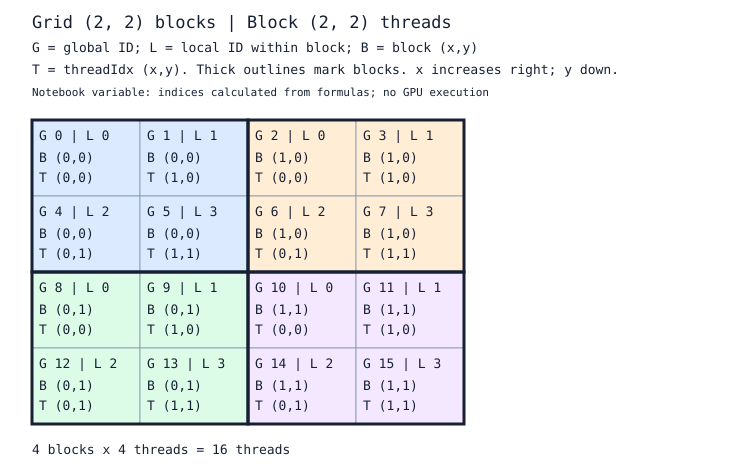

[{'global_': 0,
  'local': 0,
  'bx': 0,
  'by': 0,
  'tx': 0,
  'ty': 0,
  'x': 0,
  'y': 0},
 {'global_': 1,
  'local': 1,
  'bx': 0,
  'by': 0,
  'tx': 1,
  'ty': 0,
  'x': 1,
  'y': 0},
 {'global_': 2,
  'local': 0,
  'bx': 1,
  'by': 0,
  'tx': 0,
  'ty': 0,
  'x': 2,
  'y': 0},
 {'global_': 3,
  'local': 1,
  'bx': 1,
  'by': 0,
  'tx': 1,
  'ty': 0,
  'x': 3,
  'y': 0}]

In [12]:
from pathlib import Path
from IPython.display import SVG, display
import runpy

# Edit these two variables and rerun this cell.
grid = (2, 2)    # Blocks in x and y
block = (2, 2)   # Threads per block in x and y

assert len(grid) == len(block) == 2
assert all(type(d) is int and 1 <= d <= 16 for d in (*grid, *block))

tools = runpy.run_path("exercises/03-gpu-exec-model/05-thread-indexing/draw-indices.py")
thread_data = list(tools["reference_records"](*grid, *block))

output_dir = Path("thread-indexing-output")
output_dir.mkdir(exist_ok=True)
image_path = tools["draw"](*grid, *block, output_dir / "custom.svg", records=thread_data)
display(SVG(filename=str(image_path)))

# Inspect the first four threads. Use thread_data to inspect all of them.
thread_data[:4]

## Exercise 03: GPU Execution Model
**Time: 25 min**

Each thread fills one pixel with its indexing information. Compare **16 threads** arranged in four different ways. Block colours and thick borders show block membership.

Every pixel contains:

- **G:** global thread ID, unique across the grid.
- **L:** flattened local thread ID, restarting from zero in each block.
- **B:** block coordinates `(blockIdx.x, blockIdx.y)`.
- **T:** thread coordinates `(threadIdx.x, threadIdx.y)`.

For 1D launches, `G = blockIdx.x * blockDim.x + threadIdx.x`, and `L = threadIdx.x`.

For 2D launches, we use a row-major image layout:

```cpp
int x = blockIdx.x * blockDim.x + threadIdx.x;
int y = blockIdx.y * blockDim.y + threadIdx.y;
int width = gridDim.x * blockDim.x;
int global = y * width + x;
int local = threadIdx.y * blockDim.x + threadIdx.x;
```

The flattened global ID in this exercise follows **image row order**, not block order. Thread IDs describe data positions, not execution order.



In [ ]:
!cat exercises/03-gpu-exec-model/05-thread-indexing/thread-indexing.cu

In [ ]:
!cmake -G Ninja -S exercises -B exercises/build -DCMAKE_BUILD_TYPE=Release -DEXERCISES_EXTRA_SOURCES=""
!cmake --build exercises/build --parallel 4 --target ex-03-gpu-exec-model-05-thread-indexing


### Observations

Record how changing the block shape changes local IDs and block membership while every global pixel still has a unique ID.